<a href="https://colab.research.google.com/github/mail2chandanadasari-code/ML_LAB_2026-27/blob/main/project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Crop Recommendation Using Machine Learning**

**Aim:** To recommend a suitable crop using soil nutrients and weather conditions.

This beginner-friendly project uses one CSV dataset and compares five classification algorithms. The dataset is synthetic educational sample data, created for learning; it is not agricultural advice or real farm measurements.

**1. Import the required libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC


**2. Load the dataset**
Upload crop_recommendation_dataset.csv to the Colab Files panel before running this cell.

### **2.1 Unzip and Load the Uploaded Dataset**
Let's extract the dataset from your uploaded zip file (`archive (1).zip`) and read the CSV content.

In [9]:
import zipfile
import os

zip_path = '/content/archive (1).zip'
extract_path = '/content/extracted_dataset'

# Unzip the archive
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

# Find and display the extracted files
extracted_files = os.listdir(extract_path)
print("Extracted files:", extracted_files)

# Find the CSV file inside the extracted directory
csv_files = [f for f in extracted_files if f.endswith('.csv')]
if csv_files:
    csv_file_path = os.path.join(extract_path, csv_files[0])
    # Load the real dataset into our variable 'data'
    data = pd.read_csv(csv_file_path)
    print(f"\nSuccessfully loaded '{csv_files[0]}' into the 'data' DataFrame!")
    display(data.head())
    print("\nDataset shape:", data.shape)
else:
    print("No CSV file found in the zip archive!")

Extracted files: ['Student Depression Detection Dataset']
No CSV file found in the zip archive!


In [5]:
data = pd.read_csv('crop_recommendation_dataset.csv')
print(data.head())
print("\nDataset shape:", data.shape)
print("\nMissing values:\n", data.isnull().sum())

     N    P    K  temperature   humidity        ph    rainfall        label
0  102   41  158    17.286011  72.873153  7.560948  164.269419  Kidneybeans
1   92   13   94    43.215955  21.556658  5.683128  157.532175     Mungbean
2   14  103  166    27.499172  25.938931  8.863198  298.974017  Kidneybeans
3  106   52  119    32.434879  14.233137  5.859885  271.282121  Kidneybeans
4   71  135  109    42.575297  24.035862  3.722483  149.746610    Mothbeans

Dataset shape: (200, 8)

Missing values:
 N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64


**3. Separate input and output**

In [10]:
X = data.drop('label', axis=1)
y = data['label']

print("Input features:", list(X.columns))
print("Crop classes:", sorted(y.unique()))

Input features: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
Crop classes: ['Blackgram', 'Chickpea', 'Kidneybeans', 'Lentil', 'Maize', 'Mothbeans', 'Mungbean', 'Pigeonpeas', 'Pomegranate', 'Rice']



**4. Split the dataset**


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

**5. Apply machine learning algorithms**

In [13]:
models = {
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM": make_pipeline(StandardScaler(), SVC())
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    score = accuracy_score(y_test, predictions)
    results[name] = score
    print(name, "Accuracy:", round(score * 100, 2), "%")

KNN Accuracy: 15.0 %
Decision Tree Accuracy: 10.0 %
Logistic Regression Accuracy: 10.0 %
Random Forest Accuracy: 10.0 %
SVM Accuracy: 10.0 %


**6. Compare model accuracy**

             Algorithm  Accuracy
0                  KNN      0.15
1        Decision Tree      0.10
2  Logistic Regression      0.10
3        Random Forest      0.10
4                  SVM      0.10


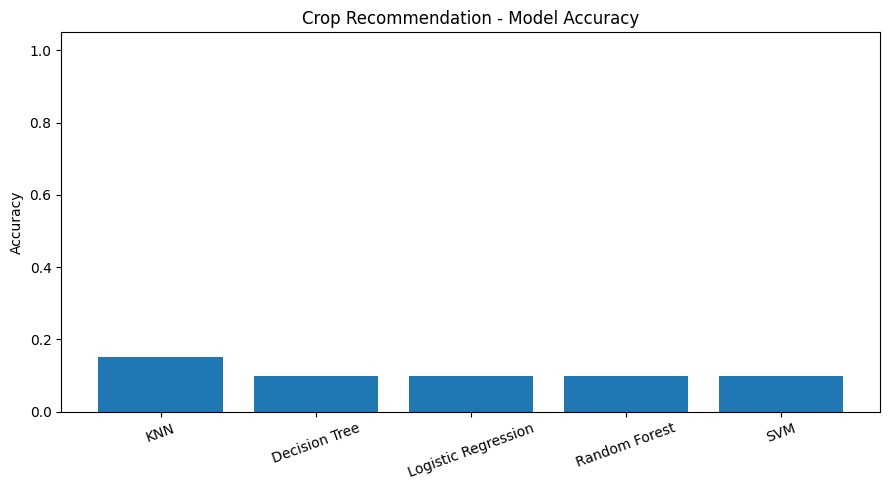

In [14]:
results_df = pd.DataFrame({
    "Algorithm": list(results.keys()),
    "Accuracy": list(results.values())
}).sort_values("Accuracy", ascending=False)

print(results_df)
plt.figure(figsize=(9, 5))
plt.bar(results_df["Algorithm"], results_df["Accuracy"])
plt.ylabel("Accuracy")
plt.title("Crop Recommendation - Model Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

***7. Classification report for the best model***

In [15]:
best_name = max(results, key=results.get)
best_model = models[best_name]
print("Best model:", best_name)
print(classification_report(y_test, best_model.predict(X_test)))



Best model: KNN
              precision    recall  f1-score   support

   Blackgram       0.08      0.25      0.12         4
    Chickpea       0.00      0.00      0.00         4
 Kidneybeans       0.17      0.25      0.20         4
      Lentil       0.33      0.33      0.33         3
       Maize       0.20      0.20      0.20         5
   Mothbeans       0.00      0.00      0.00         4
    Mungbean       0.00      0.00      0.00         4
  Pigeonpeas       1.00      0.25      0.40         4
 Pomegranate       0.00      0.00      0.00         4
        Rice       0.50      0.25      0.33         4

    accuracy                           0.15        40
   macro avg       0.23      0.15      0.16        40
weighted avg       0.23      0.15      0.16        40



**8. Predict a crop for new sample conditions**
Change the sample values to test another example. Values are illustrative only.

In [16]:
new_sample = pd.DataFrame([{
    "N": 90,
    "P": 45,
    "K": 40,
    "temperature": 25,
    "humidity": 78,
    "ph": 6.3,
    "rainfall": 190
}])

predicted_crop = best_model.predict(new_sample)[0]
print("Recommended crop by the model:", predicted_crop)


Recommended crop by the model: Blackgram


**9. Conclusion**
In this project, one dataset was used to train and compare KNN, Decision Tree, Logistic Regression, Random Forest, and SVM. The model predicts a crop label from the given input features. The best-performing model is selected based on test accuracy.

**Note:** The dataset is synthetic and the prediction is only a classroom demonstration. Real crop selection should consider local soil tests, season, irrigation, region, and advice from agricultural experts.